1: `data_exploration.ipynb`

2: `question_answering.ipynb`

3: RAG

pre-req: `pip install faiss-cpu sentence-transformers transformers datasets torch scikit-learn pandas matplotlib seaborn pathlib`

# 1: `data_exploration.ipynb`

# Preliminary Exploration of Jeopardy! Questions Dataset

In [1]:
import json

with open("JEOPARDY_QUESTIONS1.json", "r", encoding="utf-8") as f:
    data = json.load(f)

In [2]:
print(f"Total questions: {len(data)}")
print(data[0])

Total questions: 216930
{'category': 'HISTORY', 'air_date': '2004-12-31', 'question': "'For the last 8 years of his life, Galileo was under house arrest for espousing this man's theory'", 'value': '$200', 'answer': 'Copernicus', 'round': 'Jeopardy!', 'show_number': '4680'}


In [3]:
import pandas as pd

df = pd.DataFrame(data)

print(df.shape)
display(df.head())

(216930, 7)


,category,air_date,question,value,answer,round,show_number
0,HISTORY,2004-12-31,"'For the last 8 years of his life, Galileo was...",$200,Copernicus,Jeopardy!,4680
1,ESPN's TOP 10 ALL-TIME ATHLETES,2004-12-31,'No. 2: 1912 Olympian; football star at Carlis...,$200,Jim Thorpe,Jeopardy!,4680
2,EVERYBODY TALKS ABOUT IT...,2004-12-31,'The city of Yuma in this state has a record a...,$200,Arizona,Jeopardy!,4680
3,THE COMPANY LINE,2004-12-31,"'In 1963, live on ""The Art Linkletter Show"", t...",$200,McDonald\'s,Jeopardy!,4680
4,EPITAPHS & TRIBUTES,2004-12-31,"'Signer of the Dec. of Indep., framer of the C...",$200,John Adams,Jeopardy!,4680


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print(f"Number of samples: {len(df):,}")
print(f"Number of columns: {df.shape[1]}")
print("\nColumns and data types:")
print(df.dtypes)

display(df.head(10))

Number of samples: 216,930
Number of columns: 7

Columns and data types:
category       str
air_date       str
question       str
value          str
answer         str
round          str
show_number    str
dtype: object


,category,air_date,question,value,answer,round,show_number
0,HISTORY,2004-12-31,"'For the last 8 years of his life, Galileo was...",$200,Copernicus,Jeopardy!,4680
1,ESPN's TOP 10 ALL-TIME ATHLETES,2004-12-31,'No. 2: 1912 Olympian; football star at Carlis...,$200,Jim Thorpe,Jeopardy!,4680
2,EVERYBODY TALKS ABOUT IT...,2004-12-31,'The city of Yuma in this state has a record a...,$200,Arizona,Jeopardy!,4680
3,THE COMPANY LINE,2004-12-31,"'In 1963, live on ""The Art Linkletter Show"", t...",$200,McDonald\'s,Jeopardy!,4680
4,EPITAPHS & TRIBUTES,2004-12-31,"'Signer of the Dec. of Indep., framer of the C...",$200,John Adams,Jeopardy!,4680
5,3-LETTER WORDS,2004-12-31,"'In the title of an Aesop fable, this insect s...",$200,the ant,Jeopardy!,4680
6,HISTORY,2004-12-31,'Built in 312 B.C. to link Rome & the South of...,$400,the Appian Way,Jeopardy!,4680
7,ESPN's TOP 10 ALL-TIME ATHLETES,2004-12-31,'No. 8: 30 steals for the Birmingham Barons; 2...,$400,Michael Jordan,Jeopardy!,4680
8,EVERYBODY TALKS ABOUT IT...,2004-12-31,"'In the winter of 1971-72, a record 1,122 inch...",$400,Washington,Jeopardy!,4680
9,THE COMPANY LINE,2004-12-31,'This housewares store was named for the packa...,$400,Crate & Barrel,Jeopardy!,4680


In [5]:
missing = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percent": df.isna().mean() * 100
})

display(missing.sort_values("Missing Count", ascending=False))

,Missing Count,Missing Percent
value,3634,1.675195
air_date,0,0.000000
category,0,0.000000
question,0,0.000000
answer,0,0.000000
round,0,0.000000
show_number,0,0.000000


In [6]:
for col in df.select_dtypes(include="object").columns:
    empty_count = df[col].fillna("").str.strip().eq("").sum()
    print(f"{col}: {empty_count:,} empty values")

category: 0 empty values
air_date: 0 empty values
question: 0 empty values
value: 3,634 empty values
answer: 0 empty values
round: 0 empty values
show_number: 0 empty values


C:\Users\maija\AppData\Local\Temp\ipykernel_6572\1135770515.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include="object").columns:


In [7]:
print(f"Fully duplicated rows: {df.duplicated().sum():,}")

print(
    f"Duplicated question texts: "
    f"{df.duplicated(subset=['question']).sum():,}"
)

print(
    f"Duplicated question-answer pairs: "
    f"{df.duplicated(subset=['question', 'answer']).sum():,}"
)

Fully duplicated rows: 0
Duplicated question texts: 798
Duplicated question-answer pairs: 379


In [8]:
duplicates = df[
    df.duplicated(subset=["question"], keep=False)
].sort_values("question")

display(duplicates.head(20))

,category,air_date,question,value,answer,round,show_number
76511,PRESIDENTIAL BIOGRAPHIES,2008-10-14,"'""A Time to Heal""'","$2,000",Gerald Ford,Double Jeopardy!,5542
144726,BOOKS BY PRESIDENTS,1998-06-29,"'""A Time to Heal""'",$400,Gerald Ford,Double Jeopardy!,3201
30412,MOVIE LOVE THEMES,1998-05-27,"'""A Whole New World""'",$400,Aladdin,Double Jeopardy!,3178
189941,SONGS FROM DISNEY FILMS,2003-02-20,"'""A Whole New World""'",$800,Aladdin,Double Jeopardy!,4259
59633,WHAT'S THE PITCH?,1996-01-16,"'""A mind is a terrible thing to waste""'",$500,United Negro College Fund (UNCF),Jeopardy!,2622
196438,SLOGANS,1997-10-07,"'""A mind is a terrible thing to waste""'",$500,United Negro College Fund,Jeopardy!,3012
57777,PROVERBIALLY SPEAKING,2010-05-04,"'""A watched pot never"" does this'",$800,boils,Jeopardy!,5912
78322,PROVERBS,1990-02-01,"'""A watched pot never"" does this'",$600,Boils,Double Jeopardy!,1254
163145,CONVERBS,2000-01-03,"'""A watched pot never"" does this'",$100,boils,Jeopardy!,3531
129361,"AUTHOR, AUTHOR!",2010-02-04,"'""Absalom, Absalom!""'",$600,Faulkner,Jeopardy!,5849


Unique categories: 27,995


,Count
category,
BEFORE & AFTER,547
SCIENCE,519
LITERATURE,496
AMERICAN HISTORY,418
POTPOURRI,401
WORLD HISTORY,377
WORD ORIGINS,371
COLLEGES & UNIVERSITIES,351
HISTORY,349


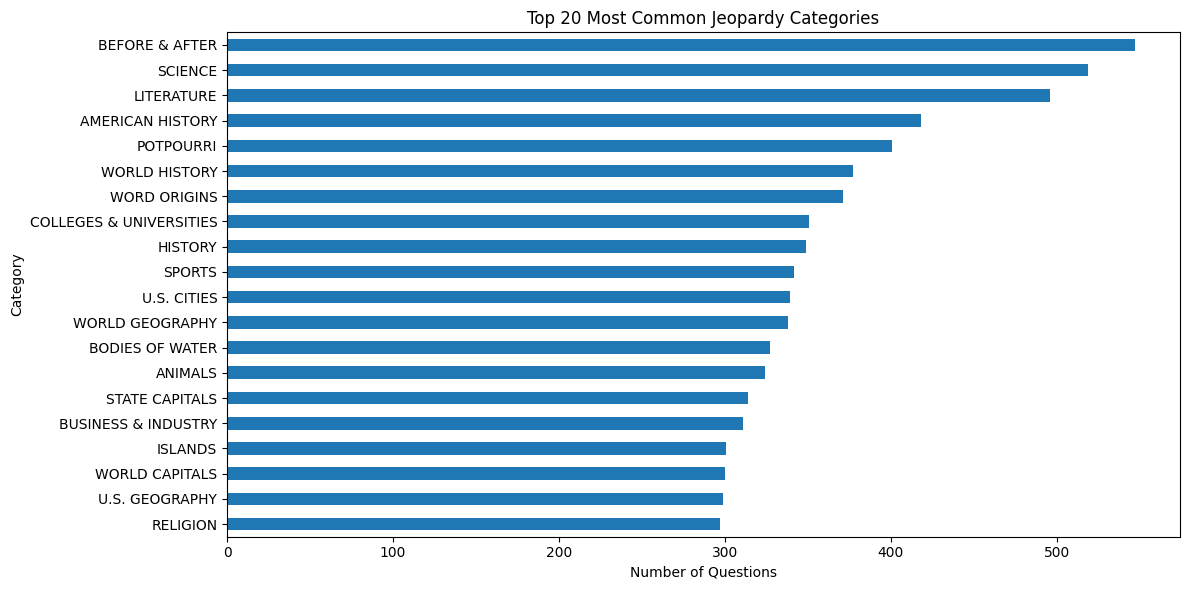

In [9]:
category_counts = df["category"].value_counts()

print(f"Unique categories: {df['category'].nunique():,}")

display(category_counts.head(20).to_frame("Count"))

plt.figure(figsize=(12, 6))
category_counts.head(20).sort_values().plot(kind="barh")

plt.xlabel("Number of Questions")
plt.ylabel("Category")
plt.title("Top 20 Most Common Jeopardy Categories")
plt.tight_layout()
plt.show()

Categories with 1 question: 1,044
Categories with <= 5 questions: 23,118
Categories with >= 20 questions: 1,246
Categories with >= 50 questions: 348


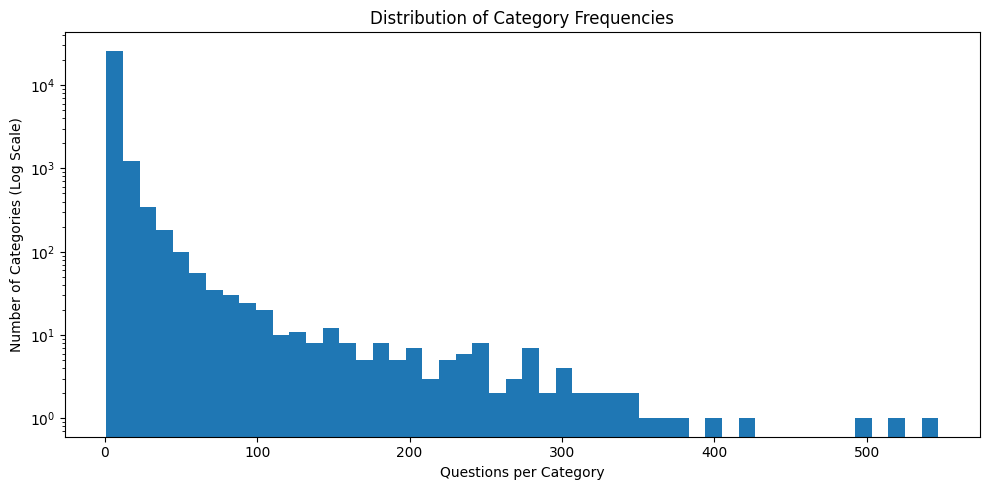

In [10]:
category_counts = df["category"].value_counts()

print(f"Categories with 1 question: {(category_counts == 1).sum():,}")
print(f"Categories with <= 5 questions: {(category_counts <= 5).sum():,}")
print(f"Categories with >= 20 questions: {(category_counts >= 20).sum():,}")
print(f"Categories with >= 50 questions: {(category_counts >= 50).sum():,}")

plt.figure(figsize=(10, 5))
plt.hist(category_counts, bins=50, log=True)

plt.xlabel("Questions per Category")
plt.ylabel("Number of Categories (Log Scale)")
plt.title("Distribution of Category Frequencies")
plt.tight_layout()
plt.show()

count    216930.000000
mean         14.562633
std           5.932564
min           1.000000
25%          11.000000
50%          15.000000
75%          18.000000
max         129.000000
Name: question_word_count, dtype: float64


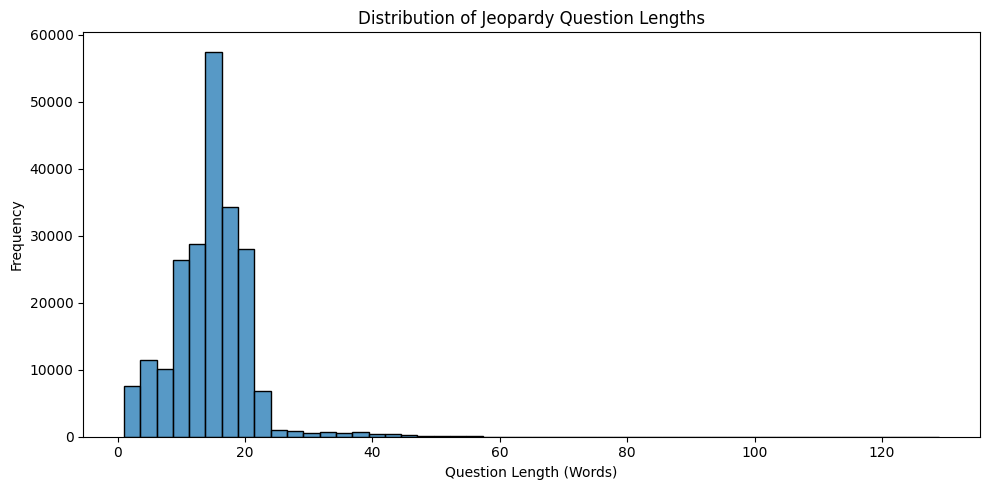

In [11]:
df["question_word_count"] = df["question"].fillna("").str.split().str.len()

print(df["question_word_count"].describe())

plt.figure(figsize=(10, 5))
sns.histplot(df["question_word_count"], bins=50)

plt.xlabel("Question Length (Words)")
plt.ylabel("Frequency")
plt.title("Distribution of Jeopardy Question Lengths")
plt.tight_layout()
plt.show()

In [12]:
display(
    df.nlargest(10, "question_word_count")[
        ["category", "question", "answer", "question_word_count"]
    ]
)

,category,question,answer,question_word_count
205763,WE LOVE BROADWAY,"'(<a href=""http://www.j-archive.com/media/2006...",The Wizard of Oz,129
100604,MUSIC,"'(<a href=""http://www.j-archive.com/media/2006...",the Empire State Building,99
179473,JERSEY BOYS,"'(<a href=""http://www.j-archive.com/media/2006...",The Four Seasons,86
24171,THEATRE: HOW NOVEL!,"'(<a href=""http://www.j-archive.com/media/2006...",Oprah Winfrey,81
7278,MUSICAL THEATRE,'1966 Jerry Herman musical that features the <...,Mame,75
72152,POP GOES THE MUSICAL,"'(<a href=""http://www.j-archive.com/media/2006...",ABBA,75
88238,THE NATIONAL ARCHIVES,"'(<a href=""http://www.j-archive.com/media/2010...",the Declaration of Independence,68
101948,BACK AT THE CBC,"'(<a href=""http://www.j-archive.com/media/2009...",an audition,68
22207,THE GREATEST IN SPORTS WITH MIKE & MIKE,"'(<a href=""http://www.j-archive.com/media/2010...",instant replay,67
436,RVs,"'(<a href=""http://www.j-archive.com/media/2010...",Mae West,65


count    216930.000000
mean          1.905486
std           1.132816
min           1.000000
25%           1.000000
50%           2.000000
75%           2.000000
max          22.000000
Name: answer_word_count, dtype: float64


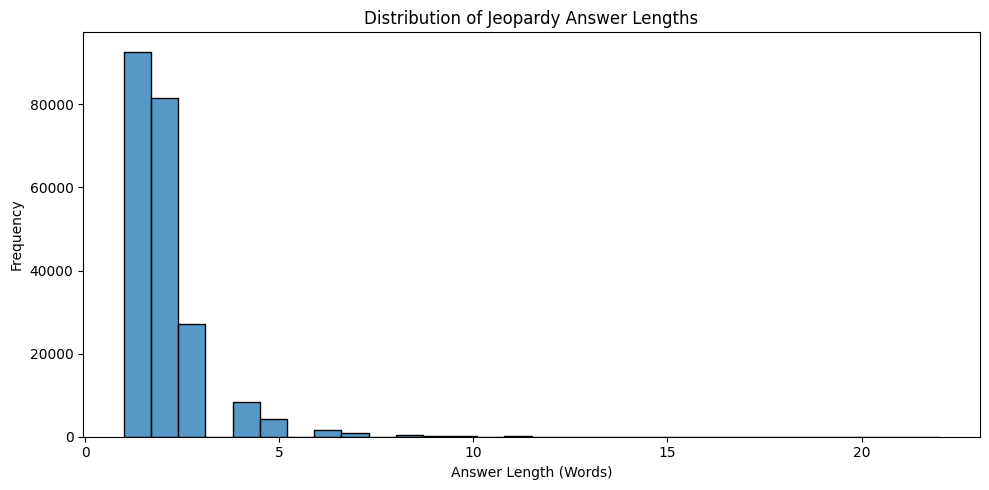

In [13]:
df["answer_word_count"] = df["answer"].fillna("").str.split().str.len()

print(df["answer_word_count"].describe())

plt.figure(figsize=(10, 5))
sns.histplot(df["answer_word_count"], bins=30)

plt.xlabel("Answer Length (Words)")
plt.ylabel("Frequency")
plt.title("Distribution of Jeopardy Answer Lengths")
plt.tight_layout()
plt.show()

In [14]:
total = len(df)

print(f"Single-word answers: {(df['answer_word_count'] == 1).sum() / total:.2%}")
print(f"1–3 word answers: {(df['answer_word_count'] <= 3).sum() / total:.2%}")
print(f"Answers over 10 words: {(df['answer_word_count'] > 10).sum() / total:.2%}")

Single-word answers: 42.73%
1–3 word answers: 92.80%
Answers over 10 words: 0.06%


In [15]:
print(df["value"].value_counts(dropna=False).head(30))

value
$400      42244
$800      31860
$200      30455
$600      20377
$1000     19539
$1200     11331
$2000     11243
$1600     10801
$100       9029
$500       9016
$300       8663
NaN        3634
$1,000     2101
$2,000     1586
$3,000      769
$1,500      546
$1,200      441
$4,000      349
$1,600      239
$2,500      232
$5,000      231
$1,400      228
$700        203
$1,800      182
$2,200      147
$2,400      127
$900        114
$6,000       85
$2,600       83
$1,300       75
Name: count, dtype: int64


count      213296.0
mean     752.595923
std      637.855303
min             5.0
25%           400.0
50%           600.0
75%          1000.0
max         18000.0
Name: value_numeric, dtype: Float64


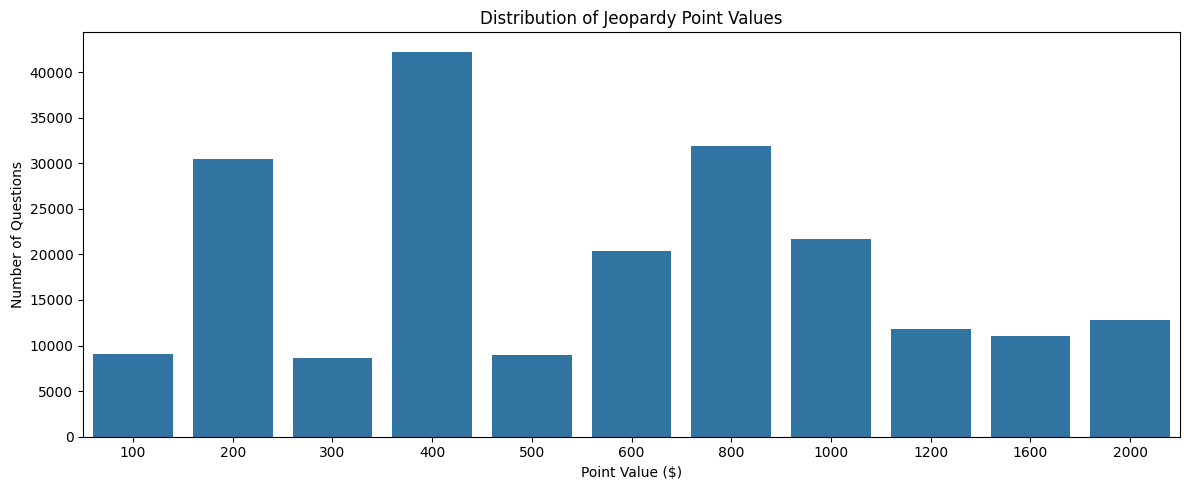

In [16]:
df["value_numeric"] = pd.to_numeric(
    df["value"].astype("string").str.replace(r"[$,]", "", regex=True),
    errors="coerce"
)

print(df["value_numeric"].describe())

plt.figure(figsize=(12, 5))
sns.countplot(
    data=df[df["value_numeric"].isin([100, 200, 300, 400, 500, 600, 800, 1000, 1200, 1600, 2000])],
    x="value_numeric",
    order=[100, 200, 300, 400, 500, 600, 800, 1000, 1200, 1600, 2000]
)

plt.xlabel("Point Value ($)")
plt.ylabel("Number of Questions")
plt.title("Distribution of Jeopardy Point Values")
plt.tight_layout()
plt.show()

,value_numeric,mean,median,count
0,5,18.666667,17.0,9
1,20,12.000000,12.0,1
2,22,21.000000,21.0,1
3,50,12.000000,12.0,1
4,100,13.168900,14.0,9029
5,200,13.836907,14.0,30455
6,250,16.800000,18.0,5
7,300,13.577052,14.0,8663
8,350,9.500000,9.5,2
9,367,22.000000,22.0,1


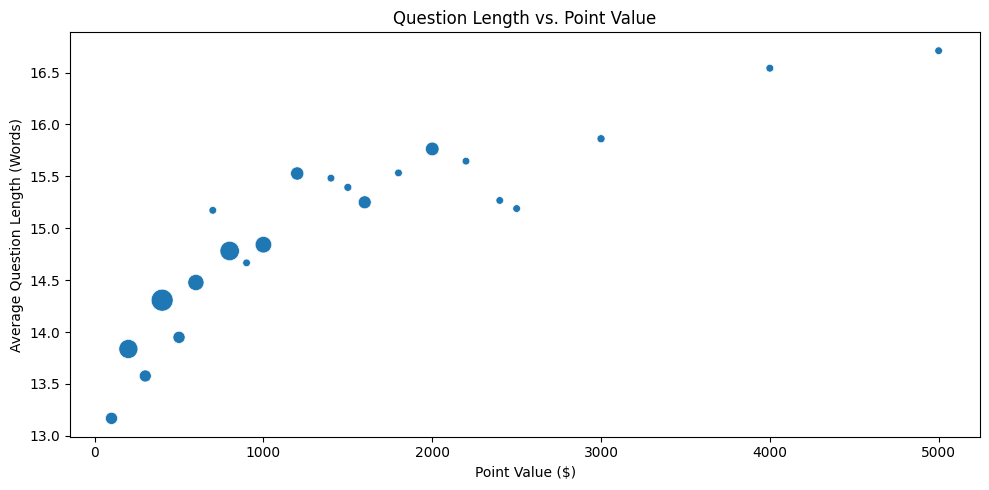

In [17]:
value_length = (
    df.dropna(subset=["value_numeric"])
      .groupby("value_numeric")["question_word_count"]
      .agg(["mean", "median", "count"])
      .reset_index()
)

display(value_length.head(20))

plot_data = value_length[value_length["count"] >= 100]

plt.figure(figsize=(10, 5))
sns.scatterplot(
    data=plot_data,
    x="value_numeric",
    y="mean",
    size="count",
    sizes=(30, 250),
    legend=False
)

plt.xlabel("Point Value ($)")
plt.ylabel("Average Question Length (Words)")
plt.title("Question Length vs. Point Value")
plt.tight_layout()
plt.show()

# 2: `question_answering.ipynb`

In [18]:
import json
import pandas as pd
import re

In [19]:
with open("JEOPARDY_QUESTIONS1.json", "r", encoding="utf-8") as f:
    data = json.load(f)

df = pd.DataFrame(data)

In [20]:
print(df.shape)
display(df.head())

(216930, 7)


,category,air_date,question,value,answer,round,show_number
0,HISTORY,2004-12-31,"'For the last 8 years of his life, Galileo was...",$200,Copernicus,Jeopardy!,4680
1,ESPN's TOP 10 ALL-TIME ATHLETES,2004-12-31,'No. 2: 1912 Olympian; football star at Carlis...,$200,Jim Thorpe,Jeopardy!,4680
2,EVERYBODY TALKS ABOUT IT...,2004-12-31,'The city of Yuma in this state has a record a...,$200,Arizona,Jeopardy!,4680
3,THE COMPANY LINE,2004-12-31,"'In 1963, live on ""The Art Linkletter Show"", t...",$200,McDonald\'s,Jeopardy!,4680
4,EPITAPHS & TRIBUTES,2004-12-31,"'Signer of the Dec. of Indep., framer of the C...",$200,John Adams,Jeopardy!,4680


In [21]:
print(f"Original dataset size: {len(df):,}")

# Find questions containing hyperlinks or embedded media
media_pattern = (
    r'<a\b|</a>|href\s*=|'
    r'<iframe\b|<video\b|<audio\b|'
    r'<img\b|<embed\b|<object\b'
)

media_mask = df["question"].str.contains(
    media_pattern,
    case=False,
    regex=True,
    na=False
)

print(f"Questions containing HTML/media: {media_mask.sum():,}")
print(f"Percentage: {media_mask.mean() * 100:.2f}%")

display(df.loc[media_mask, ["category", "question", "answer"]].head(10))

Original dataset size: 216,930
Questions containing HTML/media: 10,525
Percentage: 4.85%


,category,question,answer
29,DR. SEUSS AT THE MULTIPLEX,"'<a href=""http://www.j-archive.com/media/2004-...",Horton
39,"""X""s & ""O""s","'The shorter glass seen <a href=""http://www.j-...",an old-fashioned
40,DR. SEUSS AT THE MULTIPLEX,"'<a href=""http://www.j-archive.com/media/2004-...",Yertle
45,DR. SEUSS AT THE MULTIPLEX,"'<a href=""http://www.j-archive.com/media/2004-...",Mulberry Street
50,DR. SEUSS AT THE MULTIPLEX,"'<a href=""http://www.j-archive.com/media/2004-...",Bartholomew Cubbins
62,"GEOGRAPHY ""E""","'(<a href=""http://www.j-archive.com/media/2010...",the equator
89,SEE & SAY,"'Say the name of <a href=""http://www.j-archive...",an octopus
95,SEE & SAY,"'Say <a href=""http://www.j-archive.com/media/2...",Oregon
100,JUST THE FACTS,"'<a href=""http://www.j-archive.com/media/2010-...",a German Shepherd
101,SEE & SAY,"'Say the name of <a href=""http://www.j-archive...",the dragonfly


In [22]:
df_clean = df.loc[~media_mask].copy()

# Remove missing values in required columns
df_clean = df_clean.dropna(
    subset=["question", "category", "answer"]
)

# Remove any remaining HTML tags
df_clean["question"] = (
    df_clean["question"]
    .str.replace(r"<[^>]+>", "", regex=True)
    .str.strip()
)

df_clean["category"] = df_clean["category"].str.strip()
df_clean["answer"] = df_clean["answer"].str.strip()

# Remove empty entries
df_clean = df_clean[
    (df_clean["question"] != "") &
    (df_clean["category"] != "") &
    (df_clean["answer"] != "")
].copy()

print(f"Original: {len(df):,}")
print(f"Cleaned:  {len(df_clean):,}")
print(f"Removed:  {len(df) - len(df_clean):,}")

Original: 216,930
Cleaned:  206,405
Removed:  10,525


In [23]:
df_model = df_clean[
    ["category", "question", "answer"]
].copy()

df_model["input_text"] = (
    "Answer the Jeopardy clue.\n"
    + "Category: " + df_model["category"]
    + "\nClue: " + df_model["question"]
)

df_model["target_text"] = df_model["answer"]

display(df_model[["input_text", "target_text"]].head())

,input_text,target_text
0,Answer the Jeopardy clue.\nCategory: HISTORY\n...,Copernicus
1,Answer the Jeopardy clue.\nCategory: ESPN's TO...,Jim Thorpe
2,Answer the Jeopardy clue.\nCategory: EVERYBODY...,Arizona
3,Answer the Jeopardy clue.\nCategory: THE COMPA...,McDonald\'s
4,Answer the Jeopardy clue.\nCategory: EPITAPHS ...,John Adams


In [24]:
df_model = df_clean[
    ["category", "question", "answer"]
].copy()

def normalize_answer(text):
    text = str(text).lower().strip()
    text = re.sub(r"<[^>]+>", "", text)
    text = re.sub(r"[^\w\s]", "", text)
    text = re.sub(r"\s+", " ", text)
    return text

df_model["answer_normalized"] = (
    df_model["answer"].apply(normalize_answer)
)

df_model["input_text"] = (
    df_model["category"] + " " + df_model["question"]
)

df_model = df_model[
    df_model["answer_normalized"] != ""
].copy()

display(df_model.head())

,category,question,answer,answer_normalized,input_text
0,HISTORY,"'For the last 8 years of his life, Galileo was...",Copernicus,copernicus,"HISTORY 'For the last 8 years of his life, Gal..."
1,ESPN's TOP 10 ALL-TIME ATHLETES,'No. 2: 1912 Olympian; football star at Carlis...,Jim Thorpe,jim thorpe,ESPN's TOP 10 ALL-TIME ATHLETES 'No. 2: 1912 O...
2,EVERYBODY TALKS ABOUT IT...,'The city of Yuma in this state has a record a...,Arizona,arizona,EVERYBODY TALKS ABOUT IT... 'The city of Yuma ...
3,THE COMPANY LINE,"'In 1963, live on ""The Art Linkletter Show"", t...",McDonald\'s,mcdonalds,"THE COMPANY LINE 'In 1963, live on ""The Art Li..."
4,EPITAPHS & TRIBUTES,"'Signer of the Dec. of Indep., framer of the C...",John Adams,john adams,EPITAPHS & TRIBUTES 'Signer of the Dec. of Ind...


In [25]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    df_model,
    test_size=0.20,
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42
)

print(f"Training:   {len(train_df):,}")
print(f"Validation: {len(val_df):,}")
print(f"Testing:    {len(test_df):,}")

Training:   165,113
Validation: 20,639
Testing:    20,640


In [26]:
answer_counts = train_df["answer_normalized"].value_counts()

print("Unique training answers:", len(answer_counts))

print(
    "Answers occurring once:",
    (answer_counts == 1).sum()
)

print(
    "Answers occurring at least 5 times:",
    (answer_counts >= 5).sum()
)

display(answer_counts.head(20))

Unique training answers: 62742
Answers occurring once: 39086
Answers occurring at least 5 times: 7318


answer_normalized
australia       174
china           168
chicago         159
france          154
india           153
japan           148
california      144
canada          135
spain           133
italy           128
hawaii          119
alaska          119
paris           117
texas           115
south africa    110
mexico          110
florida         109
germany         108
ireland         107
sweden          106
Name: count, dtype: int64

In [27]:
min_answer_freq = 5

valid_answers = answer_counts[
    answer_counts >= min_answer_freq
].index

answer_to_idx = {
    answer: idx
    for idx, answer in enumerate(valid_answers)
}

idx_to_answer = {
    idx: answer
    for answer, idx in answer_to_idx.items()
}

train_filtered = train_df[
    train_df["answer_normalized"].isin(valid_answers)
].copy()

val_filtered = val_df[
    val_df["answer_normalized"].isin(valid_answers)
].copy()

test_filtered = test_df[
    test_df["answer_normalized"].isin(valid_answers)
].copy()

print("Number of answer classes:", len(answer_to_idx))
print("Training examples:", len(train_filtered))
print("Validation examples:", len(val_filtered))
print("Testing examples:", len(test_filtered))

print(
    "Test coverage:",
    f"{len(test_filtered) / len(test_df):.2%}"
)

Number of answer classes: 7318
Training examples: 84132
Validation examples: 9516
Testing examples: 9440
Test coverage: 45.74%


In [28]:
from collections import Counter

def tokenize(text):
    return re.findall(
        r"\b\w+\b",
        text.lower()
    )

word_counts = Counter()

for text in train_filtered["input_text"]:
    word_counts.update(tokenize(text))

vocab = {
    "<PAD>": 0,
    "<UNK>": 1
}

min_word_freq = 2

for word, count in word_counts.items():
    if count >= min_word_freq:
        vocab[word] = len(vocab)

print("Vocabulary size:", len(vocab))

Vocabulary size: 33443


In [29]:
max_length = 100

def encode_text(text):
    tokens = tokenize(text)

    ids = [
        vocab.get(token, vocab["<UNK>"])
        for token in tokens[:max_length]
    ]

    ids += [vocab["<PAD>"]] * (max_length - len(ids))

    return ids

In [30]:
import torch
from torch.utils.data import Dataset, DataLoader

class JeopardyDataset(Dataset):
    def __init__(self, dataframe):
        self.texts = dataframe["input_text"].tolist()

        self.labels = [
            answer_to_idx[answer]
            for answer in dataframe["answer_normalized"]
        ]

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        x = torch.tensor(
            encode_text(self.texts[idx]),
            dtype=torch.long
        )

        y = torch.tensor(
            self.labels[idx],
            dtype=torch.long
        )

        return x, y


train_dataset = JeopardyDataset(train_filtered)
val_dataset = JeopardyDataset(val_filtered)
test_dataset = JeopardyDataset(test_filtered)

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=64
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64
)

In [31]:
import torch.nn as nn

class JeopardyMLP(nn.Module):
    def __init__(self, vocab_size, num_classes,
                 embedding_dim=128, hidden_dim=256):

        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=0
        )

        self.fc1 = nn.Linear(
            embedding_dim,
            hidden_dim
        )

        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(0.3)

        self.fc2 = nn.Linear(
            hidden_dim,
            num_classes
        )

    def forward(self, x):
        embeddings = self.embedding(x)

        # Ignore padding tokens when averaging
        mask = (x != 0).unsqueeze(-1)

        embeddings = embeddings * mask

        lengths = mask.sum(dim=1).clamp(min=1)

        pooled = embeddings.sum(dim=1) / lengths

        hidden = self.fc1(pooled)
        hidden = self.relu(hidden)
        hidden = self.dropout(hidden)

        logits = self.fc2(hidden)

        return logits

In [32]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = JeopardyMLP(
    vocab_size=len(vocab),
    num_classes=len(answer_to_idx)
).to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-3
)

print(model)

JeopardyMLP(
  (embedding): Embedding(33443, 128, padding_idx=0)
  (fc1): Linear(in_features=128, out_features=256, bias=True)
  (relu): ReLU()
  (dropout): Dropout(p=0.3, inplace=False)
  (fc2): Linear(in_features=256, out_features=7318, bias=True)
)


In [33]:
num_epochs = 10

history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

for epoch in range(num_epochs):

    model.train()

    train_loss = 0
    train_correct = 0
    train_total = 0

    for x, y in train_loader:
        x = x.to(device)
        y = y.to(device)

        optimizer.zero_grad()

        logits = model(x)
        loss = criterion(logits, y)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * y.size(0)

        predictions = logits.argmax(dim=1)

        train_correct += (predictions == y).sum().item()
        train_total += y.size(0)

    model.eval()

    val_loss = 0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for x, y in val_loader:
            x = x.to(device)
            y = y.to(device)

            logits = model(x)
            loss = criterion(logits, y)

            val_loss += loss.item() * y.size(0)

            predictions = logits.argmax(dim=1)

            val_correct += (predictions == y).sum().item()
            val_total += y.size(0)

    avg_train_loss = train_loss / train_total
    avg_val_loss = val_loss / val_total

    train_acc = train_correct / train_total
    val_acc = val_correct / val_total

    history["train_loss"].append(avg_train_loss)
    history["val_loss"].append(avg_val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    print(
        f"Epoch {epoch+1}/{num_epochs} | "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Val Loss: {avg_val_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

Epoch 1/10 | Train Loss: 8.4925 | Val Loss: 8.0877 | Train Acc: 0.0043 | Val Acc: 0.0081
Epoch 2/10 | Train Loss: 7.5451 | Val Loss: 7.5318 | Train Acc: 0.0186 | Val Acc: 0.0245
Epoch 3/10 | Train Loss: 6.2624 | Val Loss: 7.0324 | Train Acc: 0.0789 | Val Acc: 0.0559
Epoch 4/10 | Train Loss: 4.7360 | Val Loss: 6.8405 | Train Acc: 0.2042 | Val Acc: 0.0776
Epoch 5/10 | Train Loss: 3.5852 | Val Loss: 6.8762 | Train Acc: 0.3341 | Val Acc: 0.0926
Epoch 6/10 | Train Loss: 2.8273 | Val Loss: 6.9746 | Train Acc: 0.4379 | Val Acc: 0.1061
Epoch 7/10 | Train Loss: 2.2988 | Val Loss: 7.1398 | Train Acc: 0.5217 | Val Acc: 0.1184
Epoch 8/10 | Train Loss: 1.8927 | Val Loss: 7.3302 | Train Acc: 0.5923 | Val Acc: 0.1215
Epoch 9/10 | Train Loss: 1.5788 | Val Loss: 7.4876 | Train Acc: 0.6467 | Val Acc: 0.1313
Epoch 10/10 | Train Loss: 1.3217 | Val Loss: 7.7353 | Train Acc: 0.6951 | Val Acc: 0.1355


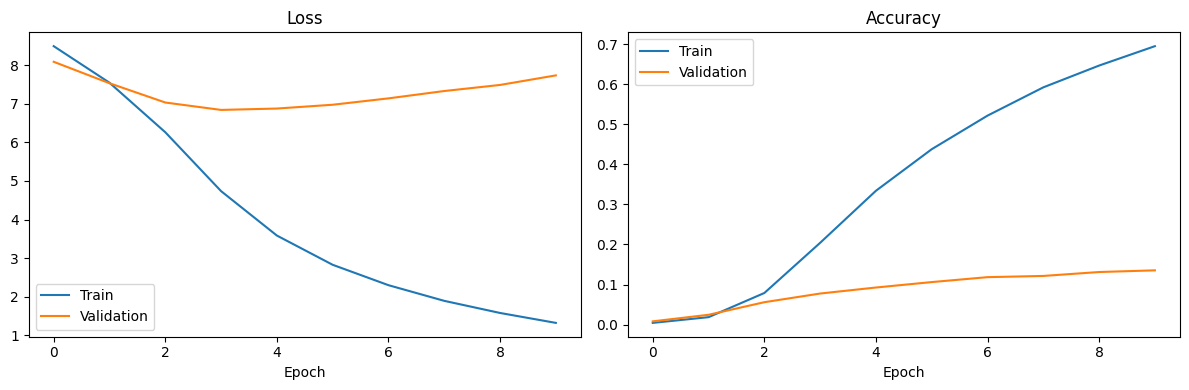

In [34]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history["train_loss"], label="Train")
axes[0].plot(history["val_loss"], label="Validation")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(history["train_acc"], label="Train")
axes[1].plot(history["val_acc"], label="Validation")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.show()

In [35]:
def predict_answer(question, category, top_k=5):
    model.eval()

    text = f"{category} {question}"

    x = torch.tensor(
        [encode_text(text)],
        dtype=torch.long
    ).to(device)

    with torch.no_grad():
        logits = model(x)
        probabilities = torch.softmax(logits, dim=1)

    scores, indices = torch.topk(
        probabilities,
        k=min(top_k, len(answer_to_idx)),
        dim=1
    )

    return [
        (idx_to_answer[idx.item()], score.item())
        for idx, score in zip(indices[0], scores[0])
    ]


sample = test_filtered.iloc[0]

print("Category:", sample["category"])
print("Question:", sample["question"])
print("Actual Answer:", sample["answer"])

print("\nModel Predictions:")

for answer, confidence in predict_answer(
    sample["question"],
    sample["category"]
):
    print(f"{answer}: {confidence:.2%}")

Category: HERSHEY'S
Question: 'Here's something to chew on: Hershey's markets the Twizzlers brand of this candy'
Actual Answer: licorice

Model Predictions:
manhattan: 9.61%
toyota: 8.25%
tea: 6.39%
greenland: 5.61%
charlotte: 4.76%


In [36]:
model.eval()

total = 0
top1_correct = 0
top5_correct = 0
top10_correct = 0
total_loss = 0

all_predictions = []
all_labels = []

with torch.no_grad():
    for x, y in test_loader:
        x = x.to(device)
        y = y.to(device)

        logits = model(x)
        loss = criterion(logits, y)

        total_loss += loss.item() * y.size(0)

        predictions = logits.argmax(dim=1)

        top1_correct += (predictions == y).sum().item()

        top5 = logits.topk(5, dim=1).indices
        top10 = logits.topk(10, dim=1).indices

        top5_correct += (
            top5 == y.unsqueeze(1)
        ).any(dim=1).sum().item()

        top10_correct += (
            top10 == y.unsqueeze(1)
        ).any(dim=1).sum().item()

        total += y.size(0)

        all_predictions.extend(predictions.cpu().tolist())
        all_labels.extend(y.cpu().tolist())

print(f"Test Loss:       {total_loss / total:.4f}")
print(f"Top-1 Accuracy:  {top1_correct / total:.2%}")
print(f"Top-5 Accuracy:  {top5_correct / total:.2%}")
print(f"Top-10 Accuracy: {top10_correct / total:.2%}")

Test Loss:       7.7340
Top-1 Accuracy:  13.82%
Top-5 Accuracy:  27.47%
Top-10 Accuracy: 35.00%


# 3: Retrieval-augmented generation

In [37]:
import faiss
from sentence_transformers import SentenceTransformer
from transformers import pipeline
from pathlib import Path

# NOTE: Part 2 already defines `device` as a torch.device used by the MLP. This section uses a
# separate name because `torch.device("cpu") == "cpu"` is False, which would break the dtype
# check for the reader below, and Part 2's `device` has no MPS option.
rag_device = "mps" if torch.backends.mps.is_available() else ("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(4)
faiss.omp_set_num_threads(4)
pd.set_option("display.max_colwidth", None)
print("rag_device:", rag_device)

rag_device: cpu


In [38]:
assert "answer_normalized" in train_df.columns   # created in Part 2


def tidy(s):
    s = str(s).replace("\\'", "'").strip()
    if len(s) >= 2 and s[0] == "'" and s[-1] == "'":
        s = s[1:-1]
    return s.strip()


def norm(text):
    """Scoring normaliser: Part 2's normalize_answer + drop a leading article."""
    return re.sub(r"^(the|a|an) ", "", normalize_answer(text)).strip()


def prep(d):
    d = d.copy()
    d["clue"] = d["question"].map(tidy)
    d["gold"] = d["answer"].map(tidy)
    d["gold_norm"] = d["answer"].map(norm)
    return d


# Adds clean-text columns; the MLP datasets/loaders built in Part 2 are unaffected.
train_df, val_df, test_df = prep(train_df), prep(val_df), prep(test_df)
print(f"train={len(train_df):,}  val={len(val_df):,}  test={len(test_df):,}")

train=165,113  val=20,639  test=20,640


In [ ]:
WIKI_CONFIG = "20231101.en" #.simple wasnt working well, as the non-english articles were probably harming results
CHUNK_WORDS = 100
CHUNKS_PER_ARTICLE = 3
MAX_ARTICLES = None          # e.g. 20000 for a quick smoke test

Path("data").mkdir(exist_ok=True)
passages_path = Path("data/wiki_passages.json")
vectors_path = Path("data/wiki_vectors.npy")


def build_passages():
    from datasets import load_dataset
    wiki = load_dataset("wikimedia/wikipedia", WIKI_CONFIG, split="train")
    if MAX_ARTICLES:
        wiki = wiki.select(range(MAX_ARTICLES))
    out = []
    for art in wiki:
        words = art["text"].split()
        for c in range(CHUNKS_PER_ARTICLE):
            chunk = " ".join(words[c * CHUNK_WORDS:(c + 1) * CHUNK_WORDS])
            if len(chunk.split()) < 15 and c > 0:
                break
            out.append({"passage_id": len(out), "title": art["title"], "chunk": c,
                        "text": f"{art['title']}: {chunk}"})
    return out


if passages_path.exists():
    passages = json.loads(passages_path.read_text())
else:
    passages = build_passages()
    passages_path.write_text(json.dumps(passages))
print(f"{len(passages):,} passages")
passages[0]

368,622 passages


{'passage_id': 0,
 'title': 'April',
 'chunk': 0,
 'text': 'April: April (Apr.) is the fourth month of the year in the Julian and Gregorian calendars, and comes between March and May. It is one of the four months to have 30 days. April always begins on the same day of the week as July, and additionally, January in leap years. April always ends on the same day of the week as December. The Month April comes between March and May, making it the fourth month of the year. It also comes first in the year out of the four months that have 30 days, as June, September and November are'}

In [40]:
encoder = SentenceTransformer(
    "sentence-transformers/multi-qa-MiniLM-L6-cos-v1",
    revision="b207367332321f8e44f96e224ef15bc607f4dbf0",
    device=rag_device,
)

if vectors_path.exists():
    vectors = np.load(vectors_path)
else:
    vectors = encoder.encode([p["text"] for p in passages], batch_size=256,
                             normalize_embeddings=True, show_progress_bar=True)
    np.save(vectors_path, vectors)

assert len(vectors) == len(passages)
index = faiss.IndexFlatIP(vectors.shape[1])   # inner product == cosine (normalised vectors)
index.add(vectors)

# Title index: lets us look an answer up by name (exact match) before falling back to dense search.
title_index = {}
for p in passages:
    key = norm(re.sub(r"\s*\(.*?\)", "", p["title"]))
    title_index.setdefault(key, []).append(p["passage_id"])
print(index.ntotal, "vectors;", len(title_index), "distinct titles")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

368622 vectors; 232801 distinct titles


In [41]:
reader = pipeline(
    "text-generation",
    model= "Qwen/Qwen2.5-1.5B-Instruct", #"Qwen/Qwen2.5-0.5B-Instruct", resulted in poor gains (still an improvement)
    #revision="7ae557604adf67be50417f59c2c2f167def9a775",
    device=rag_device,
    dtype=torch.float32 if rag_device == "cpu" else torch.float16,
    do_sample=False, temperature=1.0, top_p=1.0,
    max_new_tokens=16, return_full_text=False,
)
reader.tokenizer.padding_side = "left"   # needed for batched generation


def clean_prediction(text, clue=False):
    text = text.strip().split("\n")[0].strip()
    text = re.sub(r"^(answer|clue):\s*", "", text, flags=re.I)
    return text.strip() if clue else text.strip(" .\"'")


def generate(messages_list, max_new_tokens=16, batch_size=16, clue=False):
    outs = reader(messages_list, batch_size=batch_size, max_new_tokens=max_new_tokens)
    return [clean_prediction(o[0]["generated_text"], clue=clue) for o in outs]


def format_context(ctx):
    return "\n\n".join(f"[{i}] {p['text']}" for i, p in enumerate(ctx, 1))

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

In [42]:
N_EVAL = 1000
K_RETRIEVE = 10     # retrieved per clue (for hit-rate curve)
K_CONTEXT = 5       # passages actually shown to the reader, 3 was too small

eval_df = test_df.sample(N_EVAL, random_state=42).reset_index(drop=True)


def retrieve(categories, clues, k):
    qv = encoder.encode([f"{c}: {q}" for c, q in zip(categories, clues)], batch_size=128,
                        normalize_embeddings=True, show_progress_bar=False)
    scores, rows = index.search(qv, k)
    return [[passages[j] for j in r] for r in rows], scores


eval_ctx, eval_scores = retrieve(eval_df["category"], eval_df["clue"], K_RETRIEVE)


def show_retrieval(i, k=3):
    r = eval_df.iloc[i]
    print(f"Category: {r['category']}\nClue: {r['clue']}\nGold: {r['gold']}\n")
    return pd.DataFrame({"score": eval_scores[i][:k],
                         "passage": [p["text"] for p in eval_ctx[i][:k]]})


show_retrieval(0)

Category: CROSSWORD CLUES "D"
Clue: Oven or uncle preceder(5)
Gold: Dutch



,score,passage
0,0.445314,Oven: of them hot. History The people in the settlements of the Indus Valley Civilization were the first to have an oven inside of their mud-brick houses by 3200 B.C. People who study the history of food give credit to the Greeks for making the baking of bread into an art. A type of oven called Front-loaded bread ovens were created in ancient Greece. References Basic English 850 words Cooking appliances Home appliances Commercial kitchen equipment
1,0.414440,"Recipe: just reminded a person of the ingredients needed. History of the recipe Ancient history The earliest known recipes are from 1600 and came from an Akkadian tablet from southern Babylonia. The ancient Egyptians painted hieroglyphics showing the preparation of food. Many recipes are known from ancient Greece. Mithaecus's cookbook was an early one, but most of it has been lost. Athenaeus quotes one short recipe in his Deipnosophistae. Roman recipes are known with some of them starting in the 2nd century B.C with Cato the Elder's De Agri Cultura. Many other authors of this period explained eastern Mediterranean cooking in"
2,0.400753,"Baking: soaked them in water. Then they mixed everything together, and also mashed it. After that, this mixture was poured onto a flat, hot rock, and roasted on hot embers. This new way of making bread was much easier than the other ways of doing so. This was because bread could be made anytime if there was fire. Around 2500 BC Egyptians had bread, and may have learned how to make it from the Babylonians. Also, the Greeks around 400 B.C. tarts with patterns and honey was included in Greek food. Dispyrus, another type of baked good, was also made by"


{1: '22.3%', 3: '36.4%', 5: '41.8%', 10: '48.9%'}


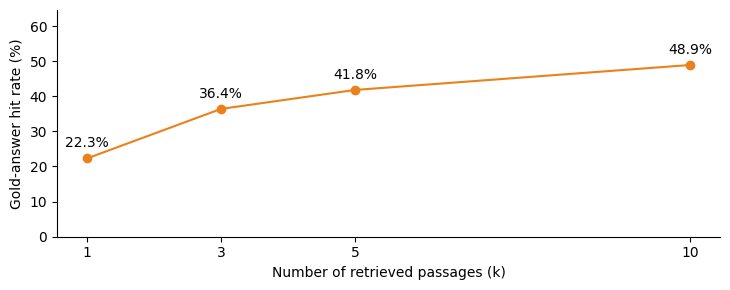

In [43]:
def contains(text, gold_norm):
    return gold_norm != "" and f" {gold_norm} " in f" {norm(text)} "


gold_norm = eval_df["gold_norm"].tolist()
hit_rates = {}
for k in (1, 3, 5, 10):
    hit_rates[k] = float(np.mean([
        any(contains(p["text"], g) for p in ctx[:k]) for g, ctx in zip(gold_norm, eval_ctx)
    ]))
print({k: f"{v:.1%}" for k, v in hit_rates.items()})

ks = list(hit_rates)
rates = [100 * hit_rates[k] for k in ks]
fig, ax = plt.subplots(figsize=(7.4, 3.0))
ax.plot(ks, rates, marker="o", color="#EB811B")
ax.set(xlabel="Number of retrieved passages (k)", ylabel="Gold-answer hit rate (%)",
       xticks=ks, ylim=(0, max(rates) * 1.3 + 1))
for k, rate in zip(ks, rates):
    ax.annotate(f"{rate:.1f}%", (k, rate), xytext=(0, 8), textcoords="offset points", ha="center")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()

In [44]:
ANSWER_SYSTEM = ("You are a Jeopardy! contestant. Use the context if it helps. "
                 "Reply with only the answer, in a few words, with no explanation.")


def build_answer_messages(category, clue, ctx=None):
    if ctx:
        user = (f"Context:\n{format_context(ctx)}\n\n"
                f"Category: {category}\nClue: {clue}\nAnswer:")
    else:
        user = f"Category: {category}\nClue: {clue}\nAnswer:"
    return [{"role": "system", "content": ANSWER_SYSTEM}, {"role": "user", "content": user}]


def answer_many(categories, clues, k=K_CONTEXT):
    ctxs, _ = retrieve(categories, clues, k)
    preds = generate([build_answer_messages(c, q, ctx) for c, q, ctx in zip(categories, clues, ctxs)])
    return preds, ctxs


# Inspect one prompt
print(build_answer_messages(eval_df.loc[0, "category"], eval_df.loc[0, "clue"],
                            eval_ctx[0][:K_CONTEXT])[1]["content"])

Context:
[1] Oven: of them hot. History The people in the settlements of the Indus Valley Civilization were the first to have an oven inside of their mud-brick houses by 3200 B.C. People who study the history of food give credit to the Greeks for making the baking of bread into an art. A type of oven called Front-loaded bread ovens were created in ancient Greece. References Basic English 850 words Cooking appliances Home appliances Commercial kitchen equipment

[2] Recipe: just reminded a person of the ingredients needed. History of the recipe Ancient history The earliest known recipes are from 1600 and came from an Akkadian tablet from southern Babylonia. The ancient Egyptians painted hieroglyphics showing the preparation of food. Many recipes are known from ancient Greece. Mithaecus's cookbook was an early one, but most of it has been lost. Athenaeus quotes one short recipe in his Deipnosophistae. Roman recipes are known with some of them starting in the 2nd century B.C with Cato the

In [ ]:
eval_df["pred_no_rag"] = generate([build_answer_messages(c, q) for c, q in zip(eval_df["category"], eval_df["clue"])])
eval_df["pred_rag"] = generate([build_answer_messages(c, q, ctx[:K_CONTEXT])
                                for c, q, ctx in zip(eval_df["category"], eval_df["clue"], eval_ctx)])
eval_df["gold_in_context"] = [any(contains(p["text"], g) for p in ctx[:K_CONTEXT])
                              for g, ctx in zip(gold_norm, eval_ctx)]
eval_df[["clue", "gold", "pred_no_rag", "pred_rag", "gold_in_context"]].head(10)

In [ ]:
def mlp_predict(categories, questions, batch_size=256):
    model.eval()
    texts = [f"{c} {q}" for c, q in zip(categories, questions)]
    preds = []
    with torch.no_grad():
        for i in range(0, len(texts), batch_size):
            x = torch.tensor([encode_text(t) for t in texts[i:i + batch_size]], dtype=torch.long).to(device)
            preds += model(x).argmax(dim=1).cpu().tolist()
    return [idx_to_answer[p] for p in preds]


eval_df["pred_mlp"] = mlp_predict(eval_df["category"], eval_df["question"])
eval_df[["clue", "gold", "pred_mlp", "pred_no_rag", "pred_rag"]].head(10)

In [ ]:
def exact_match(preds, golds):
    return np.array([norm(p) == g for p, g in zip(preds, golds)])


def contains_gold(preds, golds):
    return np.array([g != "" and g in norm(p) for p, g in zip(preds, golds)])


systems = {
    "MLP classifier (Part 2)": "pred_mlp",
    "No retrieval (LLM only)": "pred_no_rag",
    f"RAG (k={K_CONTEXT})": "pred_rag",
}
for col in systems.values():
    eval_df[f"em_{col}"] = exact_match(eval_df[col], eval_df["gold_norm"])
    eval_df[f"cg_{col}"] = contains_gold(eval_df[col], eval_df["gold_norm"])

results = pd.DataFrame({
    "Exact match": {n: eval_df[f"em_{c}"].mean() for n, c in systems.items()},
    "Gold contained in prediction": {n: eval_df[f"cg_{c}"].mean() for n, c in systems.items()},
})
display((results * 100).round(2))

# Does RAG help when the retrieved context actually contains the answer?
by_ctx = {}
for n, c in systems.items():
    em = eval_df[f"em_{c}"]
    by_ctx[n] = {"Gold in retrieved context": em[eval_df["gold_in_context"]].mean(),
                 "Gold not in context": em[~eval_df["gold_in_context"]].mean()}
print(f"Gold answer in top-{K_CONTEXT} context for {eval_df['gold_in_context'].mean():.1%} of clues")
display((pd.DataFrame(by_ctx).T * 100).round(2))

### Which clues can the MLP even attempt?

The MLP's output space is `valid_answers` from Part 2 (answers seen ≥5 times in training, ~46 % of test clues). Splitting the same results by whether the gold answer is in that set shows where each system's score comes from.

In [ ]:
mlp_vocab = set(valid_answers)               # Part 2's class set
eval_df["in_mlp_vocab"] = eval_df["answer_normalized"].isin(mlp_vocab)
print(f"{eval_df['in_mlp_vocab'].mean():.1%} of the sample is answerable by the MLP")

mlp_test_top1 = top1_correct / total         # Part 2's own result on its filtered test set
print(f"(Part 2 reported {mlp_test_top1:.2%} top-1 on test_filtered, which only contains MLP-answerable clues.)")

rows_out = {}
for n, c in systems.items():
    em = eval_df[f"em_{c}"]
    rows_out[n] = {"All test clues": em.mean(),
                   "MLP-answerable subset": em[eval_df["in_mlp_vocab"]].mean(),
                   "Other (answer not in MLP vocab)": em[~eval_df["in_mlp_vocab"]].mean()}
display((pd.DataFrame(rows_out).T * 100).round(2))

In [ ]:
cols = ["category", "clue", "gold", "pred_no_rag", "pred_rag"]
print("RAG right, no-retrieval wrong:")
display(eval_df[eval_df["em_pred_rag"] & ~eval_df["em_pred_no_rag"]][cols].head(5))
print("No-retrieval right, RAG wrong (context misled the reader):")
display(eval_df[~eval_df["em_pred_rag"] & eval_df["em_pred_no_rag"]][cols].head(5))

answer -> question

In [ ]:
STOPWORDS = {"the", "and", "for", "with", "from", "that", "this", "are", "was", "his", "her"}


def content_tokens(answer):
    return [t for t in norm(answer).split() if len(t) >= 3 and t not in STOPWORDS]


def leaks(clue, answer):
    clue_tokens = set(normalize_answer(clue).split())
    toks = content_tokens(answer)
    return bool(toks) and (norm(answer) in normalize_answer(clue) or any(t in clue_tokens for t in toks))


def lookup_many(answers, k=K_CONTEXT):
    """Title match first, then dense search on the answer text."""
    qv = encoder.encode(answers, batch_size=128, normalize_embeddings=True, show_progress_bar=False)
    _, rows = index.search(qv, k)
    out = []
    for a, r in zip(answers, rows):
        ids = list(title_index.get(norm(a), []))[:k]
        for j in r:
            if len(ids) >= k:
                break
            if int(j) not in ids:
                ids.append(int(j))
        out.append([passages[j] for j in ids])
    return out


def style_examples(category, n=3):
    pool = train_df[train_df["category"] == category]
    if len(pool) < n:
        pool = train_df
    return pool.sample(n, random_state=0)


CLUE_SYSTEM = ("You write Jeopardy! clues. Given an answer, write one clue about it: a single sentence of about "
               "15 words that points to the answer with 'this' or 'these' (for example 'this city' or 'this man') "
               "and never says the answer itself. Use only facts supported by the context. Output only the clue.")


def build_clue_messages(answer, category, ctx=None, forbidden=None):
    shots = "\n\n".join(f"Category: {r.category}\nAnswer: {r.gold}\nClue: {r.clue}"
                        for r in style_examples(category).itertuples())
    user = f"Example Jeopardy! clues (for style only):\n\n{shots}\n\n"
    if ctx:
        user += f"Context about the answer:\n{format_context(ctx)}\n\n"
    if forbidden:
        user += f"Do not use any of these words in the clue: {', '.join(forbidden)}\n\n"
    user += f"Category: {category}\nAnswer: {answer}\nClue:"
    return [{"role": "system", "content": CLUE_SYSTEM}, {"role": "user", "content": user}]


def make_clues(answers, categories, use_rag=True, k=K_CONTEXT):
    ctxs = lookup_many(answers, k) if use_rag else [None] * len(answers)
    clues = generate([build_clue_messages(a, c, ctx) for a, c, ctx in zip(answers, categories, ctxs)],
                     max_new_tokens=48, clue=True)
    bad = [i for i, (cl, a) in enumerate(zip(clues, answers)) if leaks(cl, a)]
    if bad:
        retry = generate([build_clue_messages(answers[i], categories[i], ctxs[i], content_tokens(answers[i]))
                          for i in bad], max_new_tokens=48, clue=True)
        for i, cl in zip(bad, retry):
            clues[i] = cl
    return clues, ctxs, len(bad)


def ask_for_clue(answer, category="POTPOURRI"):
    clues, ctxs, _ = make_clues([answer], [category])
    print("Clue:", clues[0])
    return pd.DataFrame({"passage": [p["text"] for p in ctxs[0]]})


ask_for_clue("Abraham Lincoln", "U.S. PRESIDENTS")

In [ ]:
N_GEN = 200
gen_df = test_df.sample(N_GEN, random_state=7).reset_index(drop=True)
answers, cats = gen_df["gold"].tolist(), gen_df["category"].tolist()

coverage = np.mean([norm(a) in title_index for a in answers])
print(f"{coverage:.1%} of these answers have an exact-title match in the datastore")

gen_df["clue_rag"], gen_ctx, n_retry_rag = make_clues(answers, cats, use_rag=True)
gen_df["clue_no_rag"], _, n_retry_no = make_clues(answers, cats, use_rag=False)

for col in ("clue_rag", "clue_no_rag"):
    gen_df[f"leak_{col}"] = [leaks(c, a) for c, a in zip(gen_df[col], answers)]
    pred, _ = answer_many(cats, gen_df[col].tolist())
    gen_df[f"roundtrip_{col}"] = exact_match(pred, gen_df["gold_norm"])
    gen_df[f"words_{col}"] = gen_df[col].str.split().str.len()

gen_df["words_real"] = gen_df["clue"].str.split().str.len()

summary = pd.DataFrame({
    "Clue with retrieved context": {
        "Leaks answer after retry": gen_df["leak_clue_rag"].mean(),
        "Round-trip exact match": gen_df["roundtrip_clue_rag"].mean(),
        "Mean words": gen_df["words_clue_rag"].mean()},
    "Clue without retrieval": {
        "Leaks answer after retry": gen_df["leak_clue_no_rag"].mean(),
        "Round-trip exact match": gen_df["roundtrip_clue_no_rag"].mean(),
        "Mean words": gen_df["words_clue_no_rag"].mean()},
}).T
summary["Mean words (real clues)"] = gen_df["words_real"].mean()
display(summary.round(3))

In [ ]:
display(gen_df[["category", "gold", "clue", "clue_rag", "clue_no_rag"]].head(8))